# Recruitment — Explainable AI Model Card
## วิเคราะห์การคัดเลือกผู้สมัครด้วยกราฟและคำอธิบาย
Notebook นี้แบ่งโค้ดเป็นส่วน ๆ แบบ Lab อ่านคำอธิบายแล้วรันเซลล์ตามลำดับจากบนลงล่าง
ใช้ข้อมูล `recruitment_data_cleaned.csv` และแสดงผลด้วยกราฟ แทนการพิมพ์ JSON ยาว ๆ

**คำถามหลัก:** โมเดลทำงานดีแค่ไหน ผิดพลาดแบบใด และตัวแปรใดมีผลต่อคำทำนาย?

**ขอบเขต:** ทำนาย `HiringDecision` ที่บันทึกอยู่ในข้อมูล ไม่ใช่ความสามารถจริงของผู้สมัคร
คำอธิบายโมเดลไม่ใช่หลักฐานเชิงเหตุและผล และไม่ควรใช้ผลนี้ตัดสินรับคนโดยอัตโนมัติ

## 0. Setup — เตรียมเครื่องมือ
เปิด Notebook นี้ใน VS Code หรือ Jupyter แล้วเลือก Python kernel ที่ต้องการใช้
หากยังไม่มีแพ็กเกจ ให้เอา `#` หน้า `%pip` ในเซลล์ถัดไปออกแล้วรัน จากนั้น restart kernel
ชื่อบนแกนกราฟใช้ภาษาอังกฤษเพื่อให้แสดงได้โดยไม่ต้องติดตั้งฟอนต์ไทย

In [1]:
# %pip install numpy pandas "scikit-learn>=1.2" "matplotlib>=3.9" ipykernel "lime==0.2.0.1"

In [2]:
from pathlib import Path
from math import factorial
import hashlib
import json
import sys
import numpy as np
import pandas as pd
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, roc_curve
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.metrics import PrecisionRecallDisplay, ConfusionMatrixDisplay

plt.rcParams.update({'figure.figsize': (9, 4.5), 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': False,
                     'font.size': 11, 'figure.dpi': 110})
COLORS = ['#a4acb8', '#4178a8', '#16877b', '#c97140']

## 1. โหลดและสำรวจข้อมูล
วาง CSV ไว้ในโฟลเดอร์เดียวกับ Notebook หรือแก้ `source` เป็นพาธของไฟล์
ตรวจชื่อคอลัมน์และค่าของเป้าหมายก่อนเริ่มวิเคราะห์

,Age,Gender,EducationLevel,ExperienceYears,PreviousCompanies,DistanceFromCompany,InterviewScore,SkillScore,PersonalityScore,RecruitmentStrategy,HiringDecision,_csv_row
0,26,1,2,0.0,3,26.783828,48,78,91,1,1,2
1,39,1,4,12.0,3,25.862694,35,68,80,2,1,3
2,48,0,2,3.0,2,9.920805,20,67,13,2,0,4
3,34,1,2,5.0,2,6.407751,36,27,70,3,0,5
4,30,0,1,6.0,1,43.105343,23,52,85,2,0,6


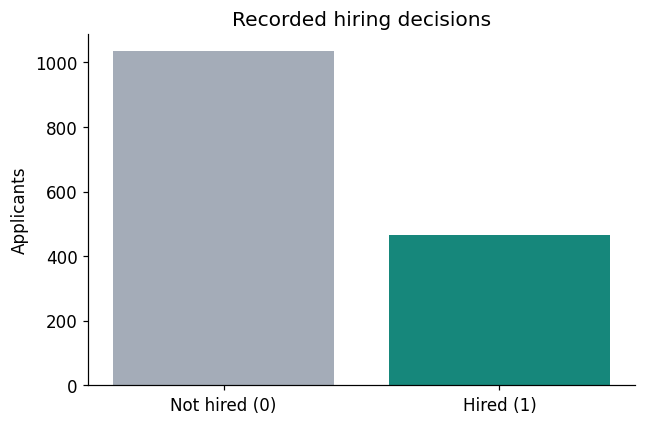

In [3]:
root = Path.cwd()
source = Path('C:\\Users\\ggez4\\Downloads\\explanai\\recruitment_data_cleaned.csv')
seed = 42
data = pd.read_csv(source)
required = ['Age', 'Gender', 'EducationLevel', 'ExperienceYears',
            'InterviewScore', 'SkillScore', 'HiringDecision']
missing_columns = sorted(set(required) - set(data.columns))
if missing_columns:
    raise ValueError(f'Missing columns: {missing_columns}')
if data.HiringDecision.isna().any() or set(data.HiringDecision.unique()) != {0, 1}:
    raise ValueError('HiringDecision must contain both 0 and 1, with no missing values.')
duplicate_count = int(data.duplicated().sum())
if duplicate_count:
    raise ValueError(f'Found {duplicate_count} duplicate rows; resolve duplicates before CV.')
data['_csv_row'] = np.arange(len(data)) + 2
raw = data.copy()
display(data.head())
fig, ax = plt.subplots(figsize=(6, 4))
counts = data.HiringDecision.value_counts().reindex([0, 1])
ax.bar(['Not hired (0)', 'Hired (1)'], counts, color=[COLORS[0], COLORS[2]])
ax.set(title='Recorded hiring decisions', ylabel='Applicants')
plt.tight_layout()
plt.show()

## 2. เตรียมข้อมูลและกำหนดตัวแปร
ใช้ EducationLevel, ExperienceYears, InterviewScore และ SkillScore เพื่อทำนาย
เก็บ Age และ Gender ไว้ตรวจผลแยกกลุ่ม ไม่ใส่เป็นตัวแปรฝึกโมเดล

ใช้ค่าประสบการณ์จาก CSV โดยไม่ใช้ Age หรือ Gender แก้ไขตัวแปรที่ใช้ฝึก
Age และ Gender ใช้ตรวจข้อมูลและผลแยกกลุ่มเท่านั้น
เติมค่ามัธยฐานและแปลงข้อมูลภายในแต่ละชุดฝึก เพื่อลดข้อมูลรั่วไหล

In [4]:
features = ['EducationLevel','ExperienceYears','InterviewScore','SkillScore']
X, y = data[features], data.HiringDecision
numeric = features[1:]
names = ['Dummy','Logistic Regression','Gradient Boosting']
params = [{},{'model__C':[0.1,1,10]},{'model__max_depth':[1,2,3], 'model__n_estimators':[50,100]}]

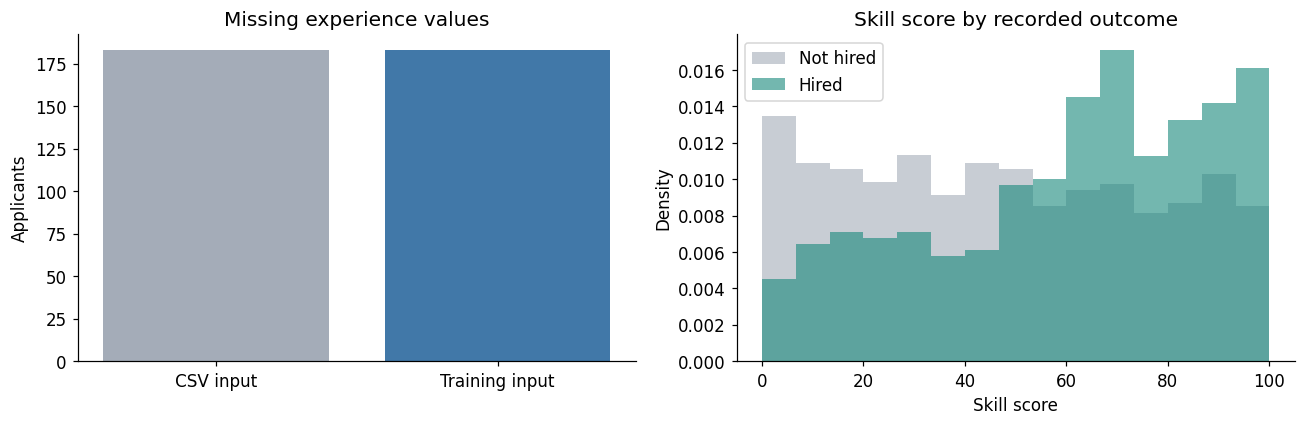

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(['CSV input', 'Training input'],
            [raw.ExperienceYears.isna().sum(), data.ExperienceYears.isna().sum()],
            color=[COLORS[0], COLORS[1]])
axes[0].set(title='Missing experience values', ylabel='Applicants')
for decision, label, color in [(0, 'Not hired', COLORS[0]), (1, 'Hired', COLORS[2])]:
    axes[1].hist(data.loc[data.HiringDecision == decision, 'SkillScore'],
                 bins=15, density=True, alpha=.6, label=label, color=color)
axes[1].set(title='Skill score by recorded outcome', xlabel='Skill score', ylabel='Density')
axes[1].legend()
plt.tight_layout()
plt.show()

### 2.1 ตรวจคุณภาพข้อมูลและอคติก่อนฝึก
ตรวจแถวซ้ำก่อนแบ่ง fold แล้ว (หากพบจะหยุดให้แก้ก่อน) ตรวจช่วงอายุ/คะแนน
ความชุกของฉลาก ข้อมูลหายรายกลุ่ม และกลยุทธ์รับสมัคร ตามแผนหน้า 2
รหัสเพศ 0/1 ใช้ตาม CSV; รายงานระบุ 0 ชาย/1 หญิง แต่ยังควรตรวจต้นทางก่อนใช้จริง
การตรวจนี้ไม่พิสูจน์ว่าไม่มีอคติ และคะแนน/ฉลากสังเคราะห์ยังต้องให้ HR ตรวจเกณฑ์
ที่มาที่ระบุในข้อเสนอ: Rabie El Kharoua, Predicting Hiring Decisions in Recruitment Data,
Kaggle, CC BY 4.0 (อ้างตามเอกสารที่ได้รับ ยังไม่ได้ยืนยันข้อมูลต้นทางออนไลน์)

**ข้อมูล 1,500 แถว · แถวซ้ำ 0 แถว**

,Age,ExperienceYears,InterviewScore,SkillScore
min,20,0.0,0,0
max,50,15.0,100,100


,n,positive_prevalence,missing_experience_csv,missing_experience_training_input
group,,,,
Gender 0,762,0.311,0.126,0.126
Gender 1,738,0.309,0.118,0.118
20–29,490,0.318,0.373,0.373
30–39,446,0.291,0.000,0.000
40+,564,0.317,0.000,0.000


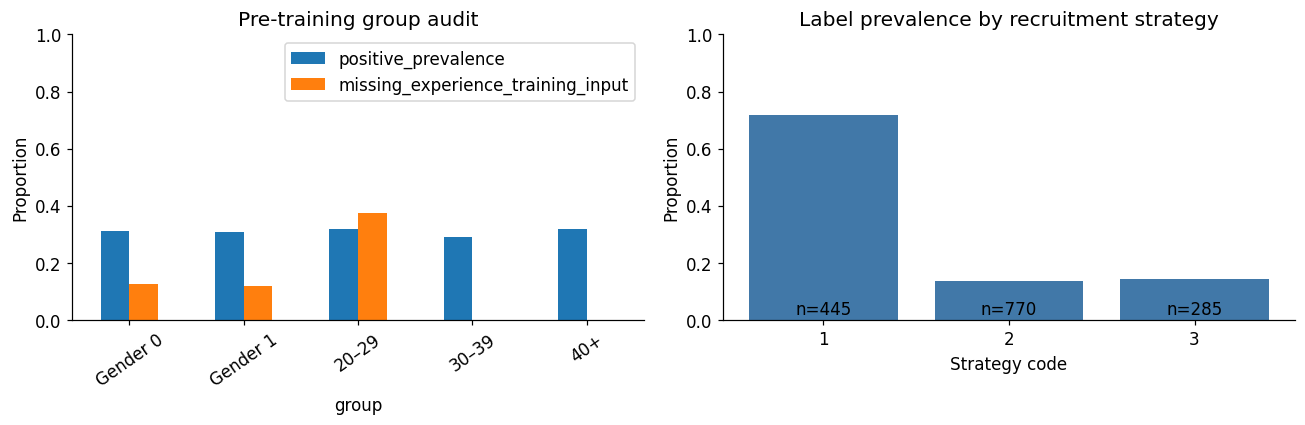

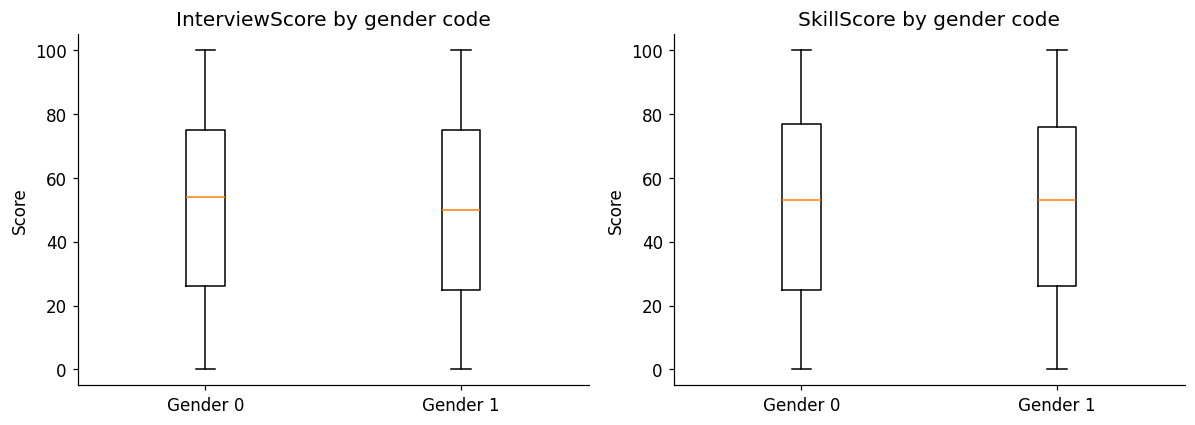

อายุนอกช่วง 20–50: **0 ราย**; ช่วงรายงาน fairness ใช้ 40 ปีขึ้นไป ไม่ตัดที่ 50

In [6]:
display(Markdown(f'**ข้อมูล {len(data):,} แถว · แถวซ้ำ {duplicate_count} แถว**'))
display(data[['Age', 'ExperienceYears', 'InterviewScore', 'SkillScore']].agg(['min','max']))
audit_groups = {'Gender 0': data.Gender.eq(0), 'Gender 1': data.Gender.eq(1),
                '20–29': data.Age.between(20,29), '30–39': data.Age.between(30,39),
                '40+': data.Age.ge(40)}
rows = []
for name, mask in audit_groups.items():
    rows.append({'group': name, 'n': int(mask.sum()),
                 'positive_prevalence': data.loc[mask,'HiringDecision'].mean(),
                 'missing_experience_csv': raw.loc[mask,'ExperienceYears'].isna().mean(),
                 'missing_experience_training_input': data.loc[mask,'ExperienceYears'].isna().mean()})
data_audit = pd.DataFrame(rows).set_index('group')
display(data_audit.round(3))
strategy = data.groupby('RecruitmentStrategy').HiringDecision.agg(['mean','size'])
fig, axes = plt.subplots(1,2,figsize=(12,4))
data_audit[['positive_prevalence','missing_experience_training_input']].plot.bar(ax=axes[0],rot=35)
axes[0].set(title='Pre-training group audit',ylabel='Proportion',ylim=(0,1))
axes[1].bar(strategy.index.astype(str),strategy['mean'],color=COLORS[1])
axes[1].set(title='Label prevalence by recruitment strategy',xlabel='Strategy code',ylabel='Proportion',ylim=(0,1))
for i,n in enumerate(strategy['size']): axes[1].text(i,.02,f'n={n}',ha='center')
plt.tight_layout(); plt.show()
fig, axes = plt.subplots(1,2,figsize=(11,4))
for ax, feature in zip(axes,['InterviewScore','SkillScore']):
    values=[data.loc[data.Gender.eq(g),feature].dropna() for g in [0,1]]
    ax.boxplot(values, tick_labels=['Gender 0','Gender 1'])
    ax.set(title=f'{feature} by gender code',ylabel='Score')
plt.tight_layout(); plt.show()
outside_age = int((~data.Age.between(20,50)).sum())
display(Markdown(f'อายุนอกช่วง 20–50: **{outside_age} ราย**; ช่วงรายงาน fairness ใช้ 40 ปีขึ้นไป ไม่ตัดที่ 50'))

### 2.2 ทำไมไม่มี epoch?
โมเดลนี้ไม่ใช่ neural network จึงไม่ใช้ลูป epoch
Logistic Regression ใช้ `max_iter=1000` เป็นเพดานรอบ solver ไม่จำเป็นต้องทำครบทุกครั้ง
Gradient Boosting เพิ่มต้นไม้ตาม `n_estimators` (จูน 50/100) และจำกัด `max_depth` (1/2/3)
5 outer × 4 inner folds เป็นการประเมิน/เลือกโมเดล ไม่ใช่ epoch
Dummy ไม่เรียนรู้แบบวน epoch; ใช้ความชุกในชุดฝึกเป็นคะแนนอ้างอิง

## 3. สร้าง Pipeline และฟังก์ชันช่วย
เปรียบเทียบ Dummy, Logistic Regression และ Gradient Boosting
ฟังก์ชันอธิบายรายบุคคลคำนวณ Shapley แบบครบทุกชุดของตัวแปรทั้ง 4 ตัว
โดยแทนค่าตัวแปรที่ยังไม่เปิดด้วยข้อมูลอ้างอิงจากชุดฝึก (interventional background)

In [7]:
def pipeline(i):
    steps = [SimpleImputer(strategy='median')]
    if i == 1:
        steps.append(StandardScaler())
    prep = ColumnTransformer([('education',OneHotEncoder(handle_unknown='ignore',sparse_output=False),[features[0]]),('numeric',make_pipeline(*steps),numeric)])
    model = [DummyClassifier(strategy='prior'),LogisticRegression(max_iter=1000),GradientBoostingClassifier(random_state=seed,learning_rate=.1)][i]
    return Pipeline([('prep',prep),('model',model)])

In [8]:
def threshold(y, p):
    fpr,tpr,cut=roc_curve(y,p,drop_intermediate=False)
    eligible=np.flatnonzero(tpr>=.9)
    return float(cut[eligible[np.argmin(fpr[eligible])]])
def summary(y,p,decision):
    y=np.asarray(y); d=np.asarray(decision)
    tp=int(sum((y==1)&d)); fp=int(sum((y==0)&d))
    fn=int(sum((y==1)&~d)); tn=int(sum((y==0)&~d))
    return dict(n=len(y),tp=tp,fp=fp,fn=fn,tn=tn,ap=float(average_precision_score(y,p)),brier=float(brier_score_loss(y,p)))

In [9]:
def shap_values(model, row, bg):
    k=len(features)
    values=[]
    for mask in range(1<<k):
        matrix=bg.copy()
        for j,feature in enumerate(features):
            if mask & (1<<j):
                matrix[feature]=row[feature]
        values.append(model.predict_proba(matrix)[:,1].mean())
    effects=np.zeros(k)
    for mask in range(1<<k):
        size=mask.bit_count()
        for j in range(k):
            if not mask & (1<<j):
                effects[j]+=factorial(size)*factorial(k-size-1)/factorial(k)*(values[mask | (1<<j)]-values[mask])
    return float(values[0]),effects

## 4. ฝึกและประเมินด้วย Nested Cross-validation
แบ่ง outer 5 folds และ inner 4 folds เลือกพารามิเตอร์ด้วย Average Precision (AP)
เลือก Gradient Boosting เมื่อ inner AP สูงกว่า Logistic Regression มากกว่า 0.01 มิฉะนั้นเลือก Logistic Regression
เลือก threshold จากผลทำนาย inner CV โดยตั้งเป้า recall อย่างน้อย 90%
เป้าหมายนี้ไม่ได้รับประกันว่า recall บน outer test จะถึง 90%

เซลล์นี้ใช้เวลาสักครู่ ผลประเมินต่อจากนี้ใช้คำทำนายของแถวที่ไม่ได้อยู่ในชุดฝึกของ outer fold นั้น

In [10]:
pred=np.zeros((len(data),4))
dec=np.zeros((len(data),4),dtype=bool)
records=[]; splits=[]; pfi=[]; fitted=[]
outer=StratifiedKFold(5,shuffle=True,random_state=seed)
for fold,(tr,te) in enumerate(outer.split(X,y),1):
    inner=StratifiedKFold(4,shuffle=True,random_state=seed+fold)
    candidates=[]; detail=[]
    for i in range(3):
        search=GridSearchCV(pipeline(i),params[i],scoring='average_precision',cv=inner)
        search.fit(X.iloc[tr],y.iloc[tr])
        model=search.best_estimator_
        inner_prob=cross_val_predict(model,X.iloc[tr],y.iloc[tr],cv=inner,method='predict_proba')[:,1]
        # Dummy has one constant score for each fitted model, so its threshold flags all.
        cut=threshold(y.iloc[tr],inner_prob) if i else float(model.named_steps['model'].class_prior_[1])
        prob=model.predict_proba(X.iloc[te])[:,1]
        pred[te,i]=prob; dec[te,i]=prob>=cut
        candidates.append(model)
        detail.append(dict(name=names[i],params=search.best_params_,cut=cut,inner_ap=float(search.best_score_)))
    chosen=2 if detail[2]['inner_ap']-detail[1]['inner_ap']>.01 else 1
    model=candidates[chosen]
    pred[te,3]=pred[te,chosen]; dec[te,3]=dec[te,chosen]
    importance=permutation_importance(model,X.iloc[te],y.iloc[te],scoring='average_precision',n_repeats=25,random_state=seed+fold)
    pfi.append(importance.importances)
    fitted.append((model,tr,te,detail[chosen]['cut']))
    splits.append(dict(fold=fold,train=len(tr),test=len(te),chosen=names[chosen],models=detail))
    for j in te:
        records.append(dict(row=int(j+2),fold=fold,y=int(y.iloc[j]),age=int(data.Age.iloc[j]),gender=int(data.Gender.iloc[j]),**{f'prob_{i}':pred[j,i] for i in range(4)},**{f'decision_{i}':int(dec[j,i]) for i in range(4)}))


display(Markdown('**ฝึกครบแล้ว — ดูผลเปรียบเทียบในกราฟด้านล่าง**'))

**ฝึกครบแล้ว — ดูผลเปรียบเทียบในกราฟด้านล่าง**

## 5. เปรียบเทียบคุณภาพโมเดล
AP ยิ่งสูงยิ่งดี ส่วน Brier score ยิ่งต่ำยิ่งดี
เส้น Precision–Recall แสดงการแลกระหว่างความแม่นของคำทำนายบวกกับการค้นหาผู้ที่มี label 1
Selected คือขั้นตอนเลือกโมเดลภายในแต่ละ fold จึงอาจให้ผลซ้ำกับโมเดลตัวใดตัวหนึ่ง

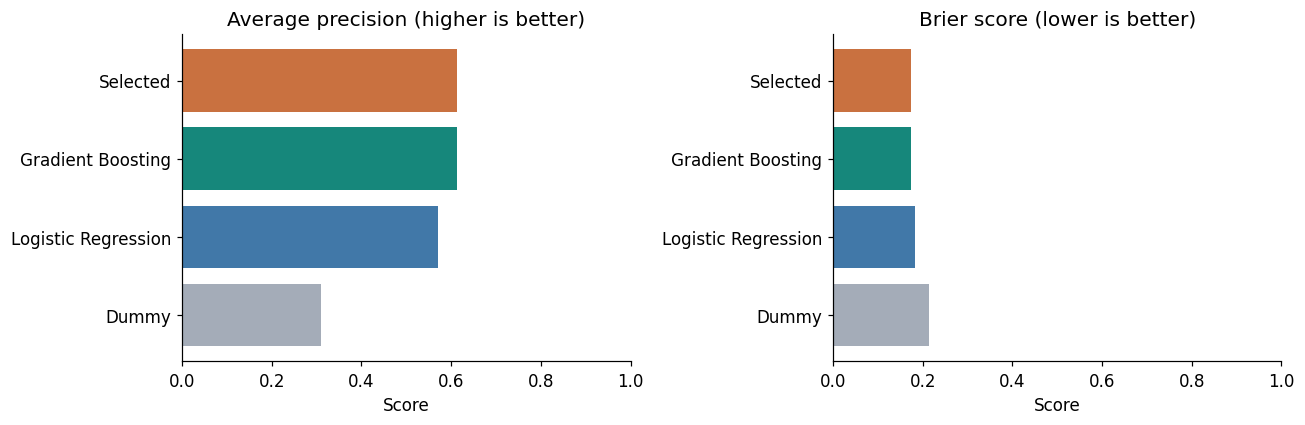

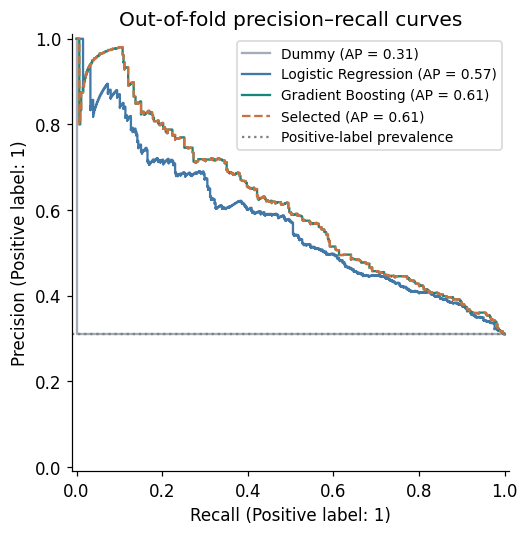

In [11]:
model_names = names + ['Selected']
metrics = pd.DataFrame({name: summary(y, pred[:, i], dec[:, i])
                        for i, name in enumerate(model_names)}).T
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, column, title in zip(axes, ['ap', 'brier'],
                            ['Average precision (higher is better)', 'Brier score (lower is better)']):
    ax.barh(model_names, metrics[column], color=COLORS)
    ax.set(title=title, xlabel='Score', xlim=(0, 1))
plt.tight_layout()
plt.show()
fig, ax = plt.subplots(figsize=(8, 5))
for i, name in enumerate(model_names):
    PrecisionRecallDisplay.from_predictions(y, pred[:, i], name=name, ax=ax,
                                           color=COLORS[i], linestyle='--' if i == 3 else '-')
ax.axhline(y.mean(), color='gray', linestyle=':', label='Positive-label prevalence')
ax.set_title('Out-of-fold precision–recall curves')
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

## 6. โมเดลผิดพลาดแบบใด?
FN = ข้อมูลระบุว่ารับเข้าทำงาน แต่โมเดลทำนายว่าไม่รับ
FP = ข้อมูลระบุว่าไม่รับ แต่โมเดลทำนายว่ารับ
คำว่า “ผิด” หมายถึงไม่ตรงกับ label ในข้อมูล ไม่ได้พิสูจน์ว่าการตัดสินใจเดิมถูกต้อง

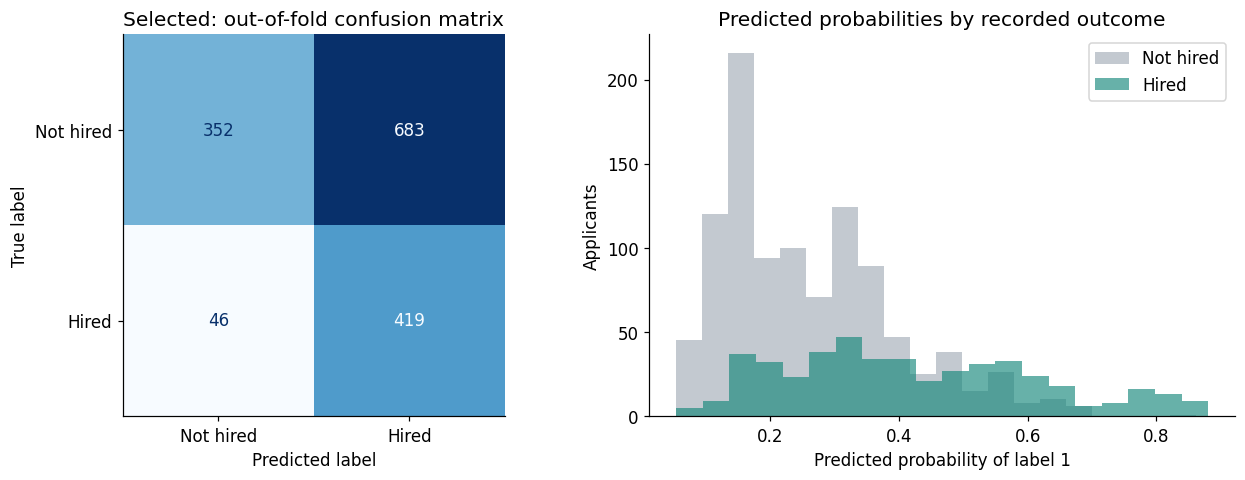

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_predictions(y, dec[:, 3].astype(int),
    display_labels=['Not hired', 'Hired'], cmap='Blues', colorbar=False, ax=axes[0])
axes[0].set_title('Selected: out-of-fold confusion matrix')
for label, value, color in [(0, 'Not hired', COLORS[0]), (1, 'Hired', COLORS[2])]:
    axes[1].hist(pred[np.asarray(y) == label, 3], bins=20, alpha=.65, label=value, color=color)
axes[1].set(title='Predicted probabilities by recorded outcome',
            xlabel='Predicted probability of label 1', ylabel='Applicants')
axes[1].legend()
plt.tight_layout()
plt.show()

## 7. ตัวแปรใดสำคัญต่อโมเดลโดยรวม?
Permutation importance คือ AP ที่ลดลงเมื่อสุ่มสลับค่าตัวแปรใน outer test fold
แท่งยิ่งยาว โมเดลยิ่งพึ่งพาตัวแปรนั้น แถบแสดง ±1 SD จาก fold และการสุ่มซ้ำรวมกัน
แถบนี้ไม่ใช่ช่วงความเชื่อมั่น และความสำคัญไม่ใช่ผลเชิงเหตุและผล

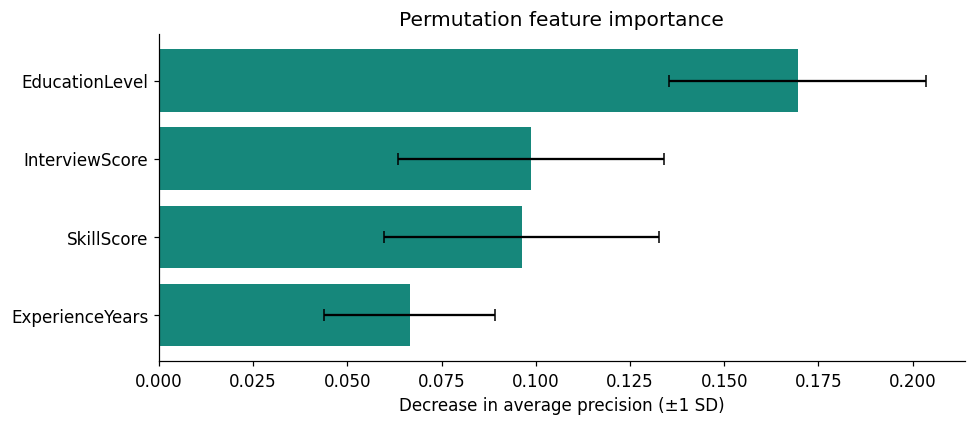

In [13]:
importance_samples = np.concatenate(pfi, axis=1)
order = np.argsort(importance_samples.mean(axis=1))
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(np.array(features)[order], importance_samples.mean(axis=1)[order],
        xerr=importance_samples.std(axis=1, ddof=1)[order], color=COLORS[2], capsize=4)
ax.axvline(0, color='gray', linewidth=1)
ax.set(title='Permutation feature importance', xlabel='Decrease in average precision (±1 SD)')
plt.tight_layout()
plt.show()

## 8. ตรวจผลแยกกลุ่ม
เปรียบเทียบ TPR (recall) กับ FPR แยกตามรหัส Gender และช่วงอายุเดิมของสคริปต์
ไม่ตีความรหัส Gender 0/1 เป็นชื่อเพศ เพราะไม่มี data dictionary ยืนยัน
กราฟนี้เป็นการตรวจเบื้องต้น ไม่มีช่วงความเชื่อมั่น และยังสรุปความเป็นธรรมไม่ได้
แม้ไม่ใช้ Age/Gender ในการฝึก ตัวแปรอื่นก็อาจสัมพันธ์กับกลุ่มเหล่านี้

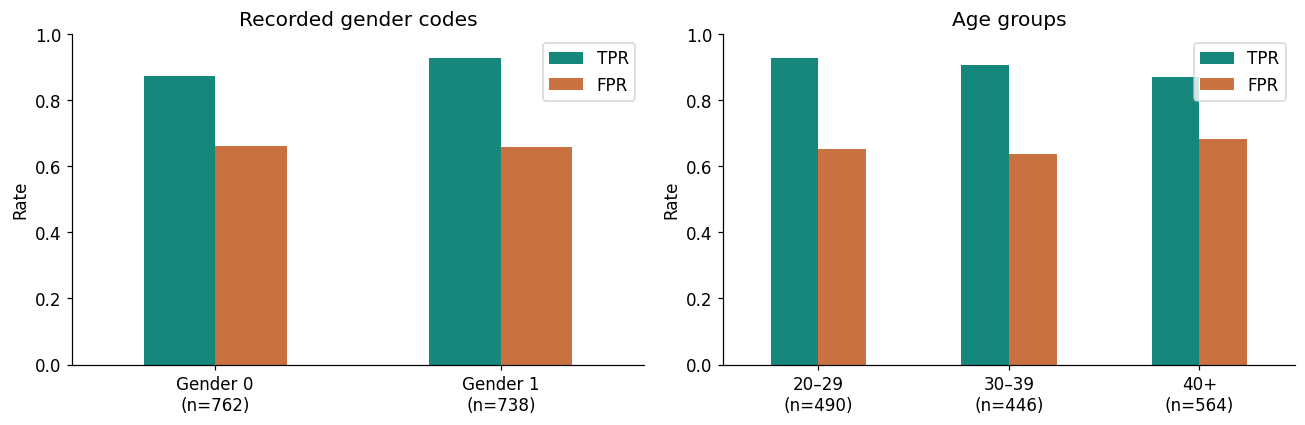

In [14]:
groups = {}
for label, mask in [('Gender 0', data.Gender == 0), ('Gender 1', data.Gender == 1),
                    ('20–29', data.Age.between(20, 29)), ('30–39', data.Age.between(30, 39)),
                    ('40+', data.Age.ge(40))]:
    if mask.any():
        groups[label] = summary(y[mask], pred[mask, 3], dec[mask, 3])
group_table = pd.DataFrame(groups).T
group_table['TPR'] = group_table.tp.div((group_table.tp + group_table.fn).replace(0, np.nan))
group_table['FPR'] = group_table.fp.div((group_table.fp + group_table.tn).replace(0, np.nan))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, subset, title in [(axes[0], ['Gender 0', 'Gender 1'], 'Recorded gender codes'),
                           (axes[1], ['20–29', '30–39', '40+'], 'Age groups')]:
    subset = [s for s in subset if s in group_table.index]
    group_table.loc[subset, ['TPR', 'FPR']].plot.bar(ax=ax, color=[COLORS[2], COLORS[3]], rot=0)
    ax.set(title=title, ylabel='Rate', ylim=(0, 1))
    ax.set_xticklabels([f'{s}\n(n={int(group_table.loc[s, "n"])})' for s in subset])
plt.tight_layout()
plt.show()

## 9. อธิบายผู้สมัครรายบุคคลด้วย Exact Shapley
เลือก FN และ FP ที่อยู่ใกล้ threshold ที่สุด อย่างละหนึ่งราย ตามวิธีเดิม
อ้างอิงผู้สมัครจากชุดฝึกของ fold นั้น สีเขียวเพิ่มและสีส้มลดความน่าจะเป็นของ label 1
ค่าฐานบวกผลรวมของทุกตัวแปรต้องเท่ากับค่าทำนาย

กราฟใช้หน่วยจุดเปอร์เซ็นต์ของความน่าจะเป็น และแถบแสดง SD จากการสุ่ม background 10 ครั้ง
ตัวอย่างเหล่านี้ไม่ใช่ตัวแทนของข้อผิดพลาดทั้งหมด และตัวแปรที่สัมพันธ์กันอาจทำให้การแทนค่าผสมไม่สมจริง

In [15]:
cases=[]
for want in ('TP','FP','FN','Near threshold'):
    hits=[]
    for fold,(model,tr,te,cut) in enumerate(fitted,1):
        for j in te:
            if want == 'Near threshold' or (want == 'TP' and y.iloc[j] == 1 and dec[j,3]) or (want=='FN' and y.iloc[j]==1 and not dec[j,3]) or (want=='FP' and y.iloc[j]==0 and dec[j,3]):
                hits.append((abs(pred[j,3]-cut),int(j),fold))
    if not hits:
        display(Markdown(f'ไม่มีตัวอย่าง {want} ในผลการประเมินนี้'))
        continue
    _,j,fold=min(hits)
    model,tr,te,cut=fitted[fold-1]
    bg=X.iloc[tr]
    base,phi=shap_values(model,X.iloc[j],bg)
    replicas=np.array([shap_values(model,X.iloc[j],bg.sample(n=100,random_state=seed+n))[1] for n in range(10)])
    residual=abs(base+phi.sum()-pred[j,3])
    assert residual<1e-10
    cases.append(dict(type=want,row=j+2,fold=fold,cut=cut,p=float(pred[j,3]),base=base,phi=phi.tolist(),residual=float(residual),top_same=int(sum(np.argmax(abs(replicas),axis=1)==np.argmax(abs(phi)))),replica_sd=replicas.std(axis=0,ddof=1).tolist(),inputs={k:None if pd.isna(v) else float(v) for k,v in X.iloc[j].items()}))

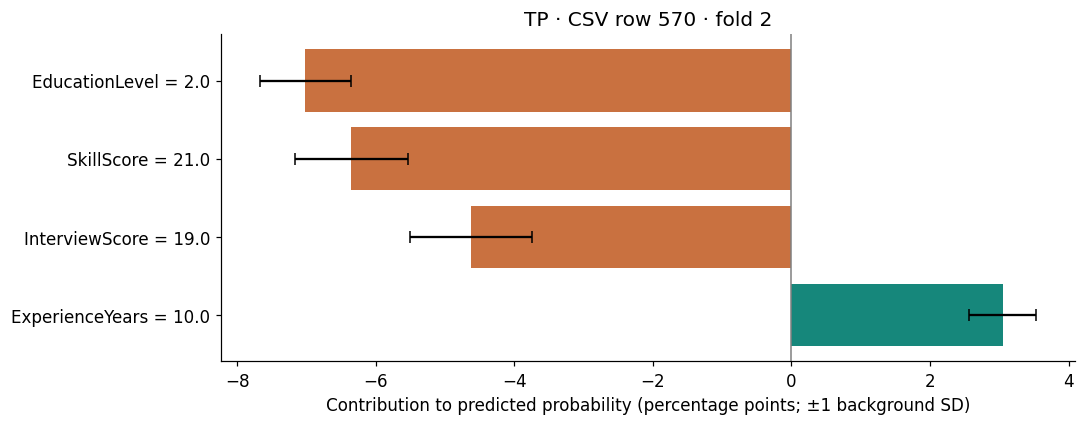

**ค่าฐาน 31.0% → ค่าทำนาย 16.1%** เทียบกับ threshold 15.8% ของ fold นี้

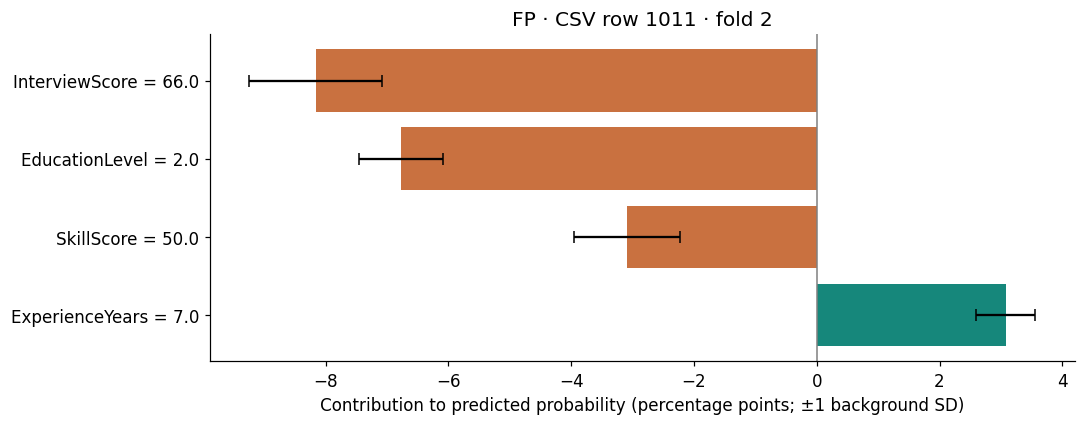

**ค่าฐาน 31.0% → ค่าทำนาย 16.0%** เทียบกับ threshold 15.8% ของ fold นี้

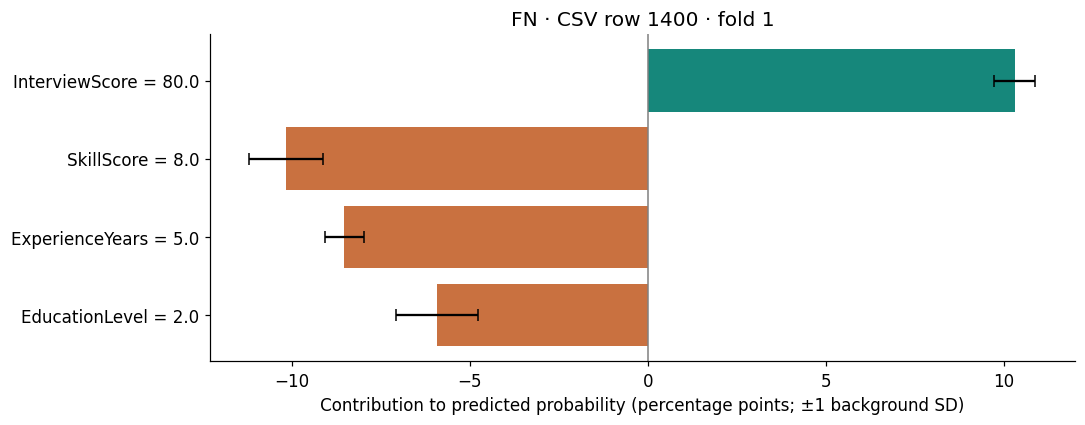

**ค่าฐาน 31.0% → ค่าทำนาย 16.7%** เทียบกับ threshold 16.9% ของ fold นี้

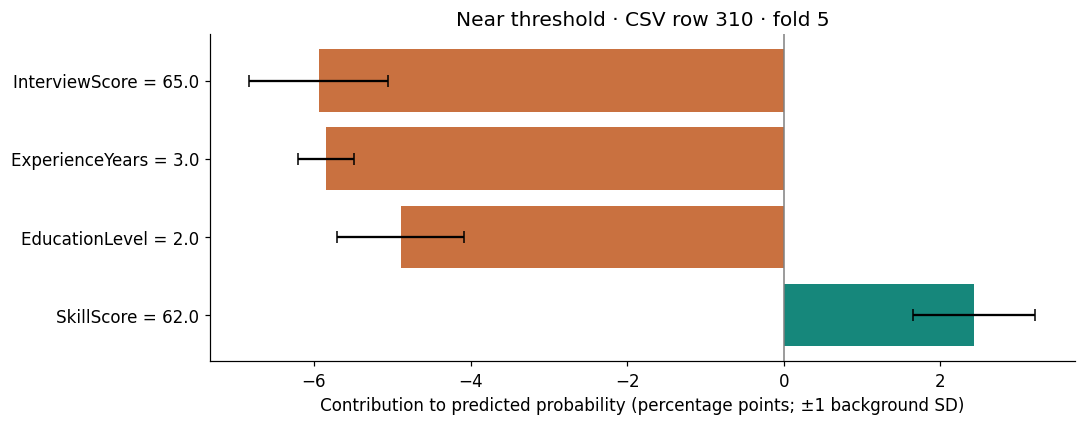

**ค่าฐาน 31.0% → ค่าทำนาย 16.8%** เทียบกับ threshold 16.8% ของ fold นี้

In [16]:
for case in cases:
    phi = np.array(case['phi']) * 100
    error = np.array(case['replica_sd']) * 100
    order = np.argsort(abs(phi))
    labels = [f"{f} = {case['inputs'][f]}" for f in np.array(features)[order]]
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.barh(labels, phi[order], xerr=error[order], capsize=4,
            color=[COLORS[2] if v >= 0 else COLORS[3] for v in phi[order]])
    ax.axvline(0, color='gray', linewidth=1)
    ax.set(title=f"{case['type']} · CSV row {case['row']} · fold {case['fold']}",
            xlabel='Contribution to predicted probability (percentage points; ±1 background SD)')
    plt.tight_layout()
    plt.show()
    display(Markdown(f"**ค่าฐาน {case['base']:.1%} → ค่าทำนาย {case['p']:.1%}** "
                     f"เทียบกับ threshold {case['cut']:.1%} ของ fold นี้"))

## 9A. ตัวชี้วัดครบตามแผนและความเป็นธรรม
ใช้คำทำนาย out-of-fold และ threshold ที่เลือกในแต่ละ fold เดิม
“ผลบวก” หมายถึงเสนอแฟ้มให้ HR ทบทวนก่อน ไม่ใช่คำสั่งรับเข้าทำงาน
แสดง sensitivity, specificity, PPV, AP, Brier และสัดส่วนเสนอทบทวน
อัตรารายกลุ่มแสดงตัวเศษ/ตัวส่วน พร้อม Wilson 95% CI; ตัวส่วนเป็นศูนย์แสดง NaN
ช่องว่างเป็น max−min ภายในมิติเดียวกัน (จุดเปอร์เซ็นต์) ไม่ใช่การทดสอบนัยสำคัญ
Wilson สมมติการสังเกตอิสระ และไม่ได้รวมความไม่แน่นอนจากการฝึกโมเดลใหม่ทุกครั้ง

,model,sensitivity,specificity,PPV,AP,prevalence,Brier,review_rate
0,Dummy,1.000,0.000,0.310,0.310,0.31,0.214,1.000
1,Logistic Regression,0.901,0.329,0.376,0.571,0.31,0.182,0.743
2,Gradient Boosting,0.901,0.340,0.380,0.614,0.31,0.175,0.735
3,Selected,0.901,0.340,0.380,0.614,0.31,0.175,0.735


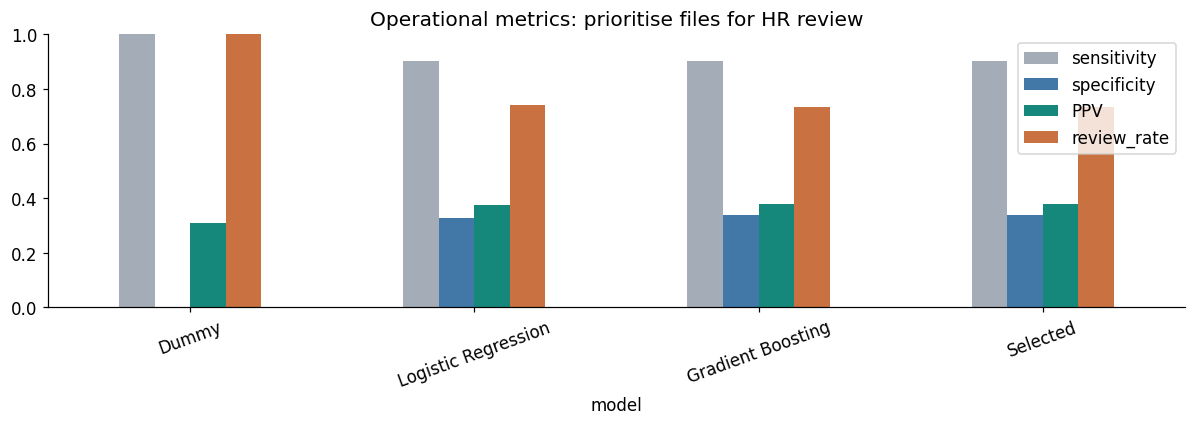

,group,dimension,n,metric,numerator,denominator,rate,ci_low,ci_high,flag
0,Gender 0,Gender,762,FNR,30,237,0.127,0.090,0.175,
1,Gender 0,Gender,762,FPR,347,525,0.661,0.619,0.700,
2,Gender 0,Gender,762,Review rate,554,762,0.727,0.694,0.757,
3,Gender 1,Gender,738,FNR,16,228,0.070,0.044,0.111,
4,Gender 1,Gender,738,FPR,336,510,0.659,0.617,0.699,
5,Gender 1,Gender,738,Review rate,548,738,0.743,0.710,0.773,
6,20–29,Age,490,FNR,11,156,0.071,0.040,0.122,
7,20–29,Age,490,FPR,218,334,0.653,0.600,0.702,
8,20–29,Age,490,Review rate,363,490,0.741,0.700,0.778,
9,30–39,Age,446,FNR,12,130,0.092,0.054,0.154,


,dimension,metric,min,max,count,gap_pp
0,Age,FNR,0.07,0.13,3,5.80
1,Age,FPR,0.64,0.68,3,4.39
2,Age,Review rate,0.72,0.74,3,2.54
3,Gender,FNR,0.07,0.13,2,5.64
4,Gender,FPR,0.66,0.66,2,0.21
5,Gender,Review rate,0.73,0.74,2,1.55


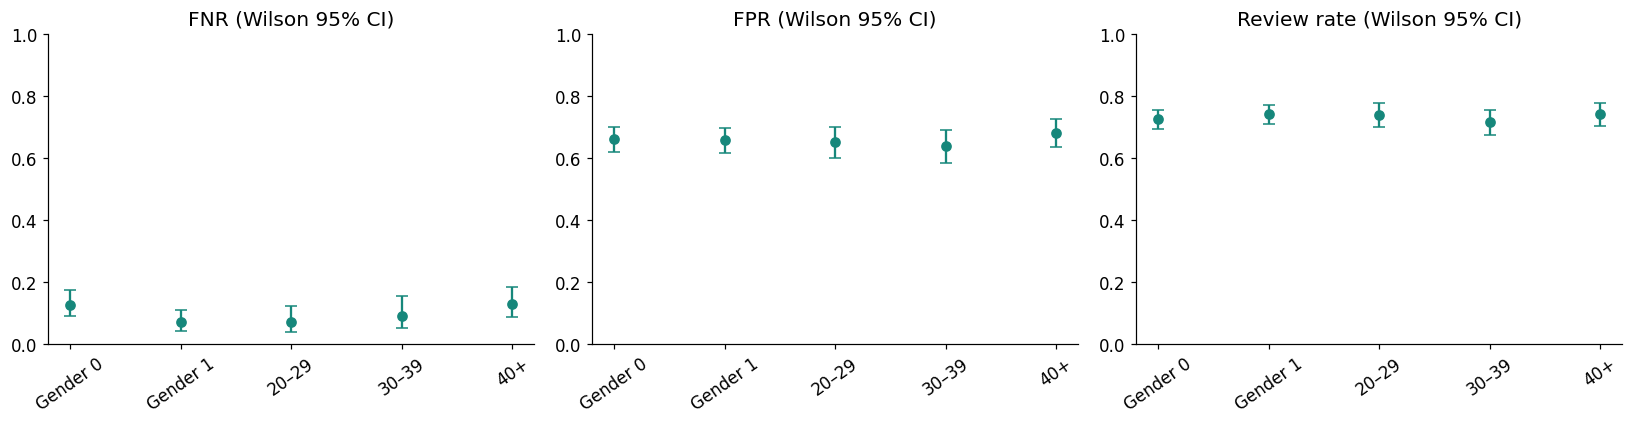

,fold,model,threshold
0,1,Gradient Boosting,0.168699
1,2,Gradient Boosting,0.157952
2,3,Gradient Boosting,0.172248
3,4,Gradient Boosting,0.167738
4,5,Gradient Boosting,0.167697


In [17]:
def safe_rate(a,b):
    return a/b if b else np.nan

def wilson(a,n,z=1.959963984540054):
    if not n: return np.nan,np.nan
    p=a/n; denominator=1+z*z/n
    center=(p+z*z/(2*n))/denominator
    half=z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/denominator
    return center-half,center+half

rows=[]
for name,m in metrics.iterrows():
    rows.append(dict(model=name,sensitivity=safe_rate(m.tp,m.tp+m.fn),
                     specificity=safe_rate(m.tn,m.tn+m.fp),PPV=safe_rate(m.tp,m.tp+m.fp),
                     AP=m.ap,prevalence=y.mean(),Brier=m.brier,
                     review_rate=(m.tp+m.fp)/m.n))
audit_metrics=pd.DataFrame(rows)
display(audit_metrics.round(3))
audit_metrics.set_index('model')[['sensitivity','specificity','PPV','review_rate']].plot.bar(
    figsize=(11,4),color=COLORS,rot=20,ylim=(0,1),title='Operational metrics: prioritise files for HR review')
plt.tight_layout(); plt.show()
fair_rows=[]
for name,mask in audit_groups.items():
    m=summary(y[mask],pred[mask,3],dec[mask,3])
    rates={'FNR':(m['fn'],m['fn']+m['tp']), 'FPR':(m['fp'],m['fp']+m['tn']),
           'Review rate':(m['tp']+m['fp'],m['n'])}
    for rate,(a,b) in rates.items():
        lo,hi=wilson(a,b)
        fair_rows.append(dict(group=name,dimension='Gender' if name.startswith('Gender') else 'Age',
            n=m['n'],metric=rate,numerator=a,denominator=b,rate=safe_rate(a,b),
            ci_low=lo,ci_high=hi,flag='no denominator' if not b else ('small denominator (<30)' if b<30 else '')))
fairness=pd.DataFrame(fair_rows)
display(fairness.round(3))
fairness_gaps=fairness.groupby(['dimension','metric'])['rate'].agg(['min','max','count']).reset_index()
fairness_gaps['gap_pp']=(fairness_gaps['max']-fairness_gaps['min'])*100
fairness_gaps.loc[fairness_gaps['count']<2,'gap_pp']=np.nan
display(fairness_gaps.round(2))
fig,axes=plt.subplots(1,3,figsize=(15,4))
for ax,metric in zip(axes,['FNR','FPR','Review rate']):
    t=fairness[fairness.metric.eq(metric)]
    ax.errorbar(np.arange(len(t)),t.rate,
                yerr=np.array([t.rate-t.ci_low,t.ci_high-t.rate]),fmt='o',capsize=4,color=COLORS[2])
    ax.set(xticks=np.arange(len(t)),xticklabels=t.group,title=metric+' (Wilson 95% CI)',ylim=(0,1))
    ax.tick_params(axis='x',rotation=35)
plt.tight_layout(); plt.show()
fold_choices=pd.DataFrame([{'fold':s['fold'],'model':s['chosen'],
                           'threshold':next(m['cut'] for m in s['models'] if m['name']==s['chosen'])}
                          for s in splits])
display(fold_choices)

## 9B. PFI แบบกลุ่มสำหรับตัวแปรสัมพันธ์กัน
ตรวจ Spearman correlation บนตัวแปรหลัก แล้วสลับคู่ที่ |ρ| ≥ 0.30
เพิ่มคู่ InterviewScore/SkillScore เป็น sensitivity check ที่กำหนดไว้ล่วงหน้า แม้ความสัมพันธ์ต่ำ
สลับแถวเดียวกันพร้อมกันทั้งคู่เพื่อคงความสัมพันธ์ภายในกลุ่ม ใช้ outer test เท่านั้น
แถบ ±1 SD รวมการสุ่มซ้ำและความต่างระหว่าง fold ไม่ใช่ confidence interval

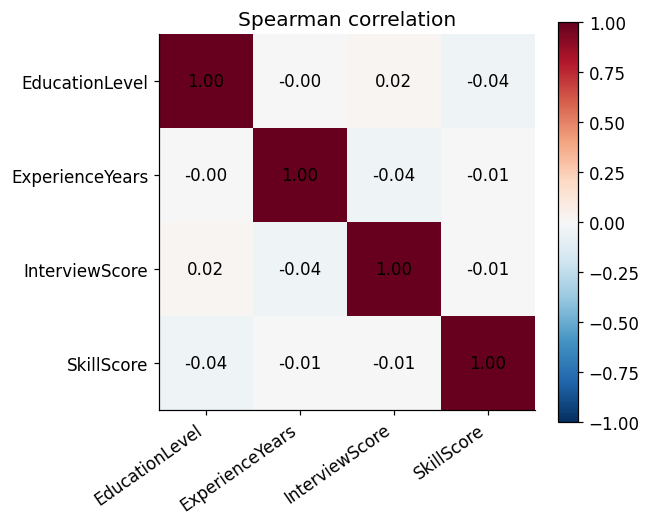

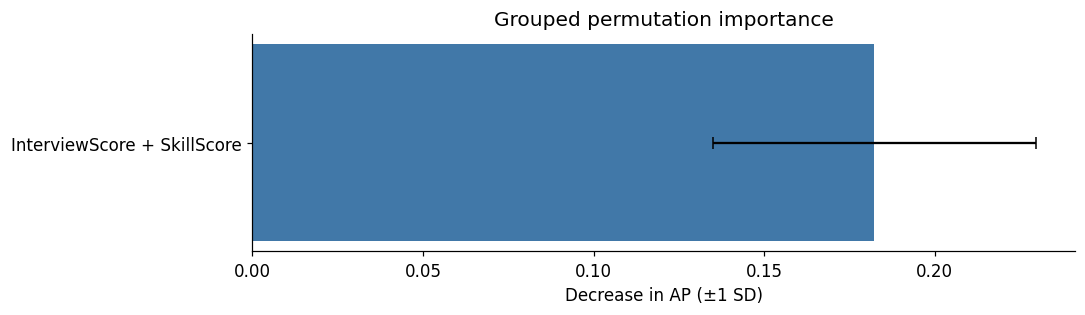

In [18]:
corr=X.corr(method='spearman')
fig,ax=plt.subplots(figsize=(6,5))
im=ax.imshow(corr,vmin=-1,vmax=1,cmap='RdBu_r')
ax.set(xticks=range(4),yticks=range(4),xticklabels=features,yticklabels=features,title='Spearman correlation')
plt.setp(ax.get_xticklabels(),rotation=35,ha='right')
for i in range(4):
    for j in range(4): ax.text(j,i,f'{corr.iloc[i,j]:.2f}',ha='center',va='center')
fig.colorbar(im,ax=ax); plt.tight_layout(); plt.show()
feature_groups=[(features[i],features[j]) for i in range(4) for j in range(i+1,4)
                if abs(corr.iloc[i,j])>=.30]
score_pair=('InterviewScore','SkillScore')
if score_pair not in feature_groups: feature_groups.append(score_pair)
group_records=[]
for fold,(model,tr,te,cut) in enumerate(fitted,1):
    baseline=average_precision_score(y.iloc[te],model.predict_proba(X.iloc[te])[:,1])
    rng=np.random.default_rng(seed+fold)
    for group in feature_groups:
        for repeat in range(25):
            shuffled=X.iloc[te].copy(); permutation=rng.permutation(len(te))
            shuffled.loc[:,list(group)]=X.iloc[te][list(group)].iloc[permutation].to_numpy()
            drop=baseline-average_precision_score(y.iloc[te],model.predict_proba(shuffled)[:,1])
            group_records.append(dict(fold=fold,repeat=repeat,group=' + '.join(group),drop=drop))
grouped_pfi=pd.DataFrame(group_records)
gt=grouped_pfi.groupby('group')['drop'].agg(['mean','std'])
fig,ax=plt.subplots(figsize=(10,max(3,len(gt)*.6)))
ax.barh(gt.index,gt['mean'],xerr=gt['std'],capsize=4,color=COLORS[1])
ax.set(title='Grouped permutation importance',xlabel='Decrease in AP (±1 SD)')
plt.tight_layout(); plt.show()

## 9C. ALE — รูปแบบคะแนนตามประสบการณ์และทักษะ
คำนวณ first-order ALE แยก outer fold: ใช้ quantile bins จากชุดฝึก
แล้ววัดผลต่างคำทำนายที่ขอบช่วงกับผู้สมัคร outer test ที่อยู่ในช่วงนั้น
สะสมและจัดศูนย์ด้วยจำนวนข้อมูลในแต่ละช่วง เส้นแต่ละสีคือหนึ่ง fold
ไม่วาดช่วงที่ไม่มีตัวอย่าง; แสดงจำนวนผู้สมัครแต่ละช่วงด้านล่าง
ALE แสดงรูปแบบของโมเดล ไม่ใช่ผลจากการเปลี่ยนคุณสมบัติจริง

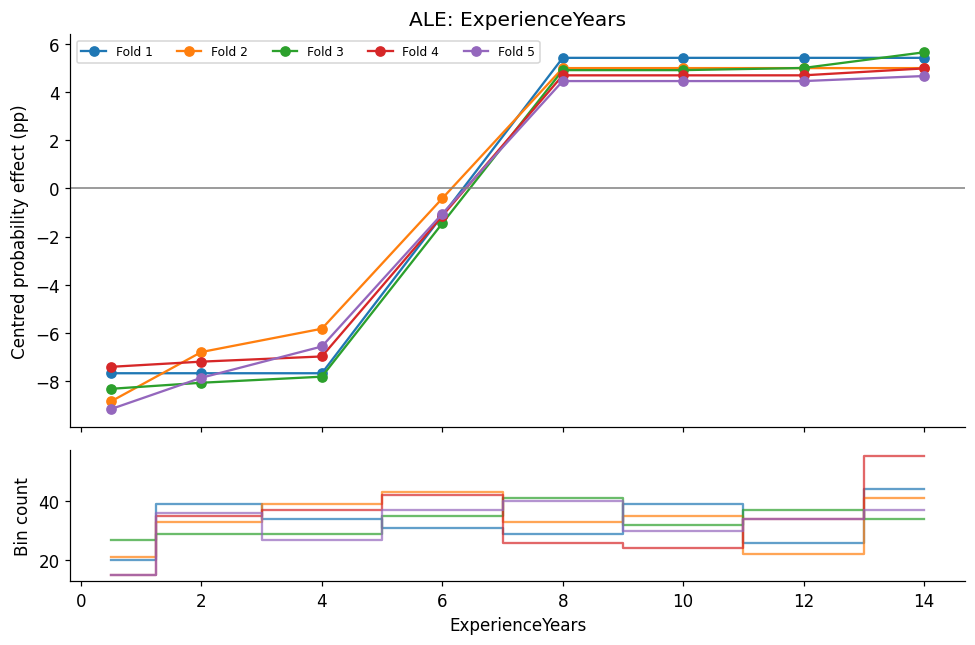

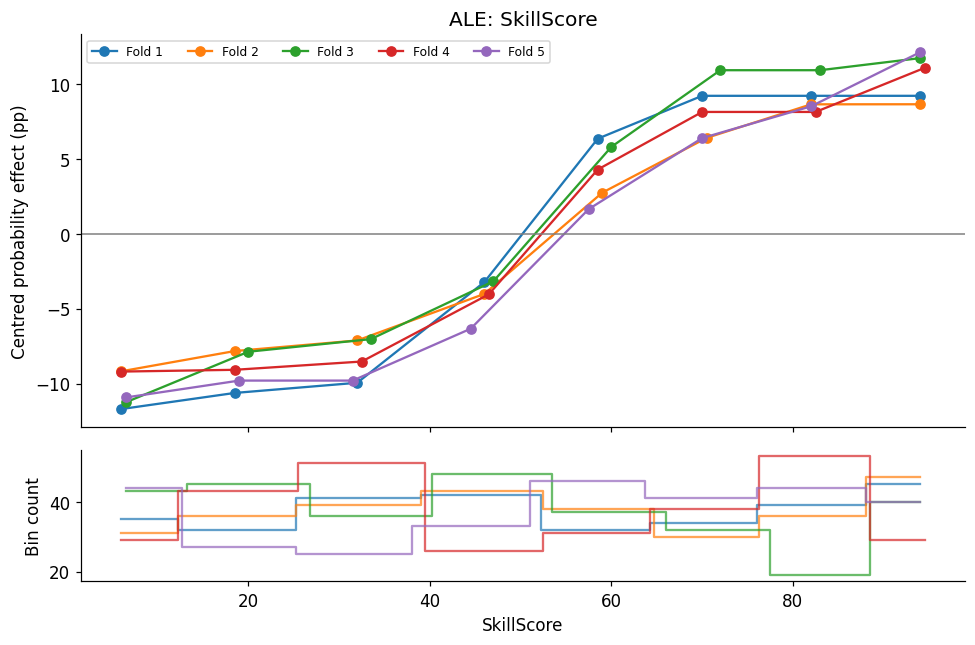

In [19]:
ale_records=[]
for feature in ['ExperienceYears','SkillScore']:
    fig,axes=plt.subplots(2,1,figsize=(9,6),sharex=True,gridspec_kw={'height_ratios':[3,1]})
    for fold,(model,tr,te,cut) in enumerate(fitted,1):
        edges=np.unique(np.quantile(X.iloc[tr][feature].dropna(),np.linspace(0,1,9)))
        values=X.iloc[te][feature].to_numpy()
        inside=np.isfinite(values)&(values>=edges[0])&(values<=edges[-1])
        bins=np.clip(np.searchsorted(edges,values,side='right')-1,0,len(edges)-2)
        effects=[]; counts=[]
        for b in range(len(edges)-1):
            mask=inside&(bins==b); part=X.iloc[te].loc[mask].copy(); counts.append(len(part))
            if len(part):
                low=part.copy(); high=part.copy()
                low[feature]=edges[b]; high[feature]=edges[b+1]
                effects.append(np.mean(model.predict_proba(high)[:,1]-model.predict_proba(low)[:,1]))
            else: effects.append(np.nan)
        effects=np.array(effects); counts=np.array(counts)
        supported=counts>0
        # Do not bridge empty intervals: each supported segment is centred separately.
        curve=np.full(len(effects),np.nan)
        for segment in np.split(np.flatnonzero(supported),np.flatnonzero(np.diff(np.flatnonzero(supported))>1)+1):
            if len(segment):
                z=np.cumsum(effects[segment])-.5*effects[segment]
                curve[segment]=z-np.average(z,weights=counts[segment])
        mid=(edges[:-1]+edges[1:])/2
        axes[0].plot(mid,curve*100,marker='o',label=f'Fold {fold}')
        axes[1].step(mid,counts,where='mid',alpha=.7,label=f'Fold {fold}')
        for b in range(len(mid)):
            ale_records.append(dict(feature=feature,fold=fold,low=edges[b],high=edges[b+1],
                                    n=int(counts[b]),ALE_pp=float(curve[b]*100)))
    axes[0].axhline(0,color='gray',linewidth=1)
    axes[0].set(title=f'ALE: {feature}',ylabel='Centred probability effect (pp)')
    axes[0].legend(ncol=5,fontsize=8)
    axes[1].set(xlabel=feature,ylabel='Bin count')
    plt.tight_layout(); plt.show()
ale_table=pd.DataFrame(ale_records)
ale_table.to_csv(root/'model_card_ale.csv',index=False)

## 9D. SHAP waterfall และความเสถียรของ background
เลือก TP, FP, FN ที่ใกล้ threshold ที่สุด และรายใกล้เกณฑ์ที่สุดโดยไม่จำกัดชนิด
หนึ่งรายอาจซ้ำระหว่างหมวดได้ จึงไม่ถือว่าเป็นตัวอย่างอิสระ
Waterfall เริ่มจากค่าเฉลี่ยคำทำนายบนชุดฝึก แล้วบวกผลแต่ละตัวแปรจนถึงคำทำนาย
ตรวจ efficiency และแสดงความถี่ที่ตัวแปรอันดับหนึ่งตรงกันจาก background 10 ชุด

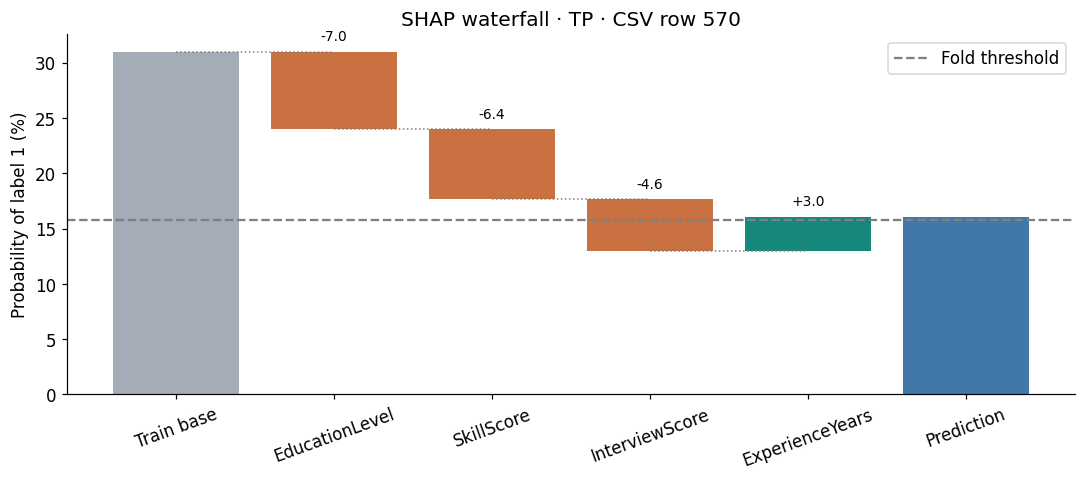

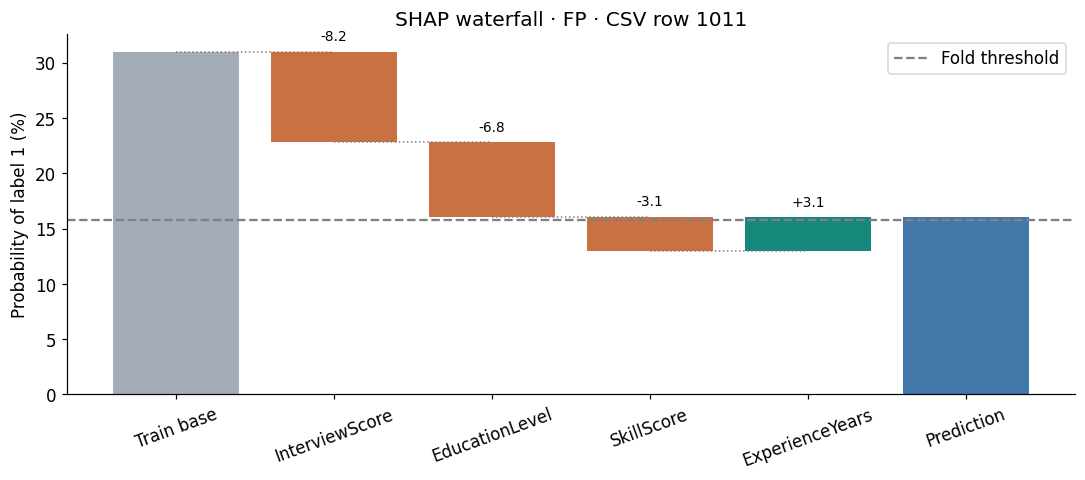

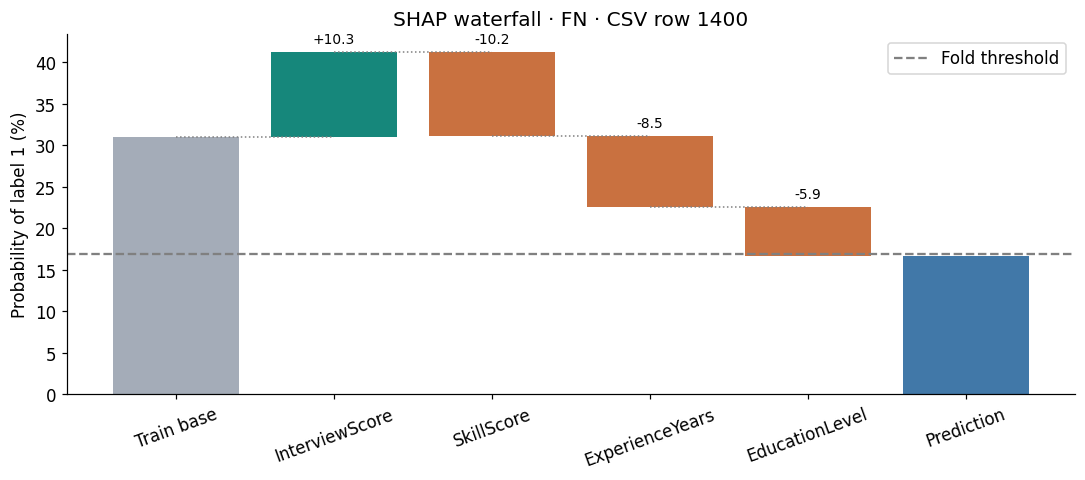

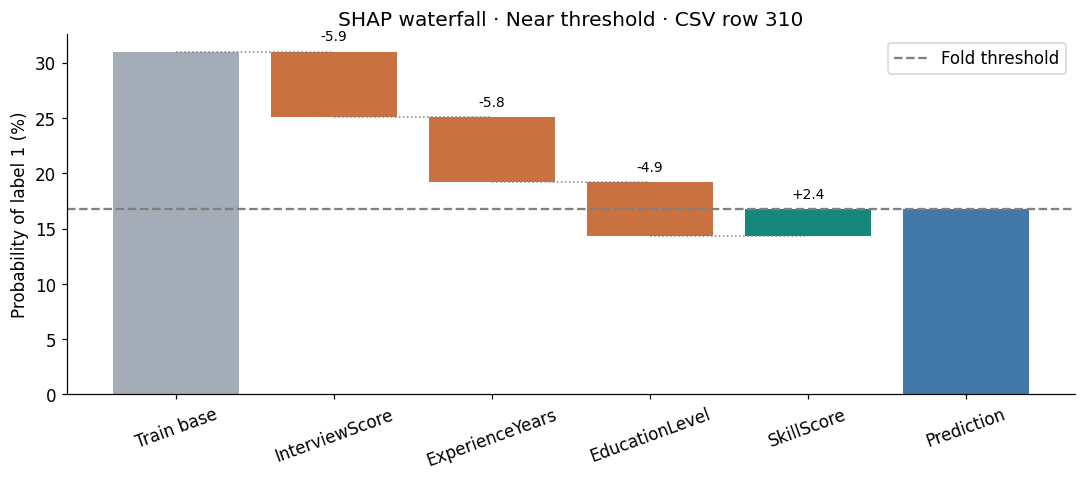

,case,row,efficiency_error,same_top_feature_out_of_10
0,TP,570,2.775558e-17,8
1,FP,1011,2.775558e-17,7
2,FN,1400,0.000000e+00,5
3,Near threshold,310,0.000000e+00,6


In [20]:
shap_checks=[]
for case in cases:
    phi=np.array(case['phi']); order=np.argsort(-abs(phi))
    fig,ax=plt.subplots(figsize=(10,4.5))
    current=case['base']*100
    ax.bar(0,current,color=COLORS[0])
    labels=['Train base']
    for k,j in enumerate(order,1):
        contribution=phi[j]*100; new=current+contribution
        ax.plot([k-1,k],[current,current],color='gray',linestyle=':',linewidth=1)
        ax.bar(k,abs(contribution),bottom=min(current,new),color=COLORS[2] if contribution>=0 else COLORS[3])
        ax.text(k,max(current,new)+1,f'{contribution:+.1f}',ha='center',fontsize=9)
        labels.append(features[j]); current=new
    ax.bar(5,case['p']*100,color=COLORS[1]); labels.append('Prediction')
    ax.axhline(case['cut']*100,color='gray',linestyle='--',label='Fold threshold')
    ax.set(xticks=range(6),xticklabels=labels,ylabel='Probability of label 1 (%)',
           title=f"SHAP waterfall · {case['type']} · CSV row {case['row']}")
    ax.tick_params(axis='x',rotation=20); ax.legend(); plt.tight_layout(); plt.show()
    assert abs(case['base']+phi.sum()-case['p'])<1e-10
    shap_checks.append(dict(case=case['type'],row=case['row'],efficiency_error=case['residual'],
                            same_top_feature_out_of_10=case['top_same']))
display(pd.DataFrame(shap_checks))

## 9E. LIME — local surrogate, fidelity และความเสถียรข้าม seed
ใช้แพ็กเกจ `lime` จริงผ่าน `LimeTabularExplainer` โดยกำหนดพารามิเตอร์คงที่ก่อนดูผล
ใช้ข้อมูลฝึกของ fold นั้นเท่านั้น ตั้ง EducationLevel เป็น categorical และแบ่งตัวเลขเป็น quartile bins
เติม missing สำหรับข้อมูลอ้างอิงด้วยมัธยฐานชุดฝึก ไม่ใช้ Age/Gender; prediction wrapper เรียก Pipeline เดิม
สุ่ม 5,000 ตัวอย่างต่อครั้ง ใช้ kernel_width = 0.75 × √4 และทดสอบ seed 0–9
weighted R² ใช้ `Explanation.score` ของแพ็กเกจ ซึ่งวัดบน neighborhood ที่ใช้ fit surrogate
จึงไม่ใช่คะแนนบน neighborhood ที่กันไว้ และเทียบตรง ๆ กับ R² ของวิธีเดิมไม่ได้
บันทึกคำอธิบาย HTML จากแพ็กเกจสำหรับ seed 0 ของแต่ละกรณีใน `lime_explanations`
การสุ่มอาจสร้างข้อมูลที่ไม่สมจริง และการใช้แพ็กเกจจริงไม่รับประกันว่า fidelity จะสูง
เอกสารวิธีใช้: https://lime-ml.readthedocs.io/en/latest/lime.html

ใช้แพ็กเกจ **lime 0.2.0.1** — 5,000 samples × 10 seeds ต่อกรณี

weighted_R2               absolute_error              
                      mean    min    max           mean    min    max
case                                                                 
FN                   0.483  0.472  0.495          0.131  0.122  0.136
FP                   0.229  0.213  0.239          0.005  0.001  0.010
Near threshold       0.244  0.224  0.254          0.019  0.014  0.023
TP                   0.280  0.263  0.298          0.006  0.002  0.009

,case,most_common_top,top_agreement,agreement_with_SHAP_top,mean_weighted_R2
0,TP,EducationLevel,1.0,1.0,0.280
1,FP,EducationLevel,1.0,0.0,0.229
2,FN,InterviewScore,1.0,1.0,0.483
3,Near threshold,EducationLevel,1.0,0.0,0.244


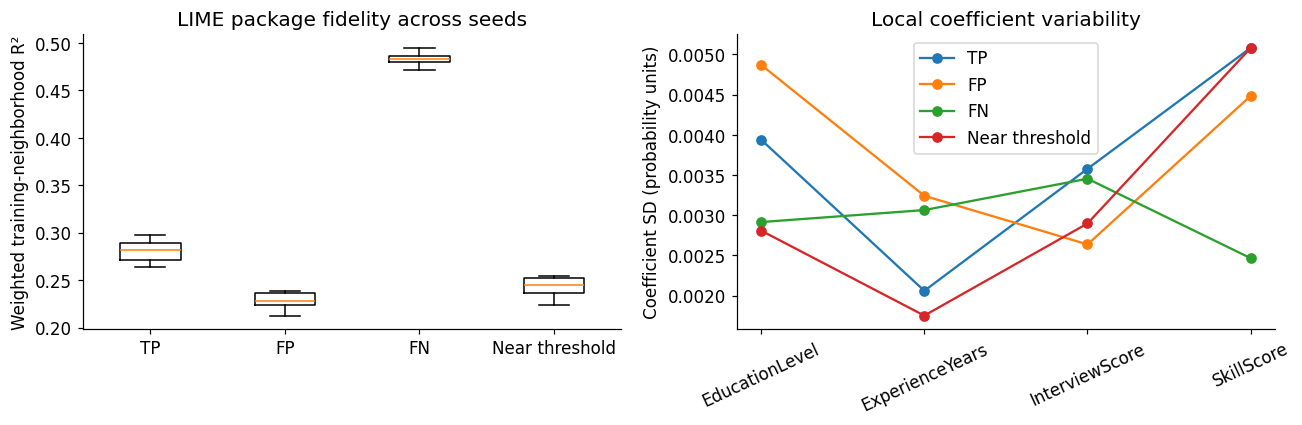

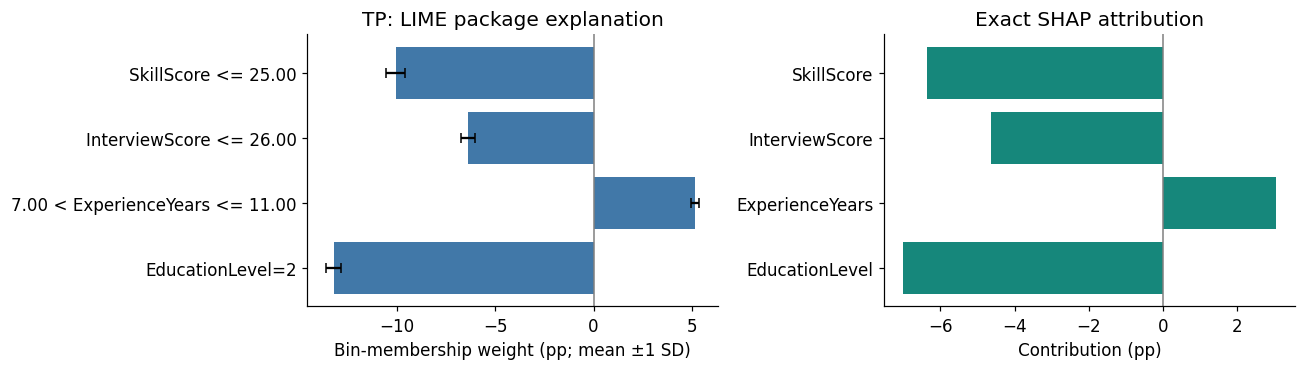

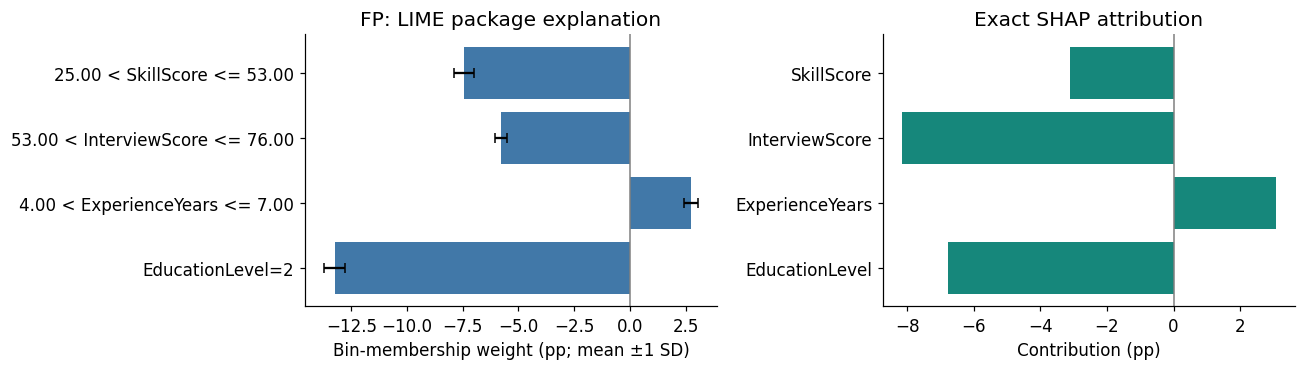

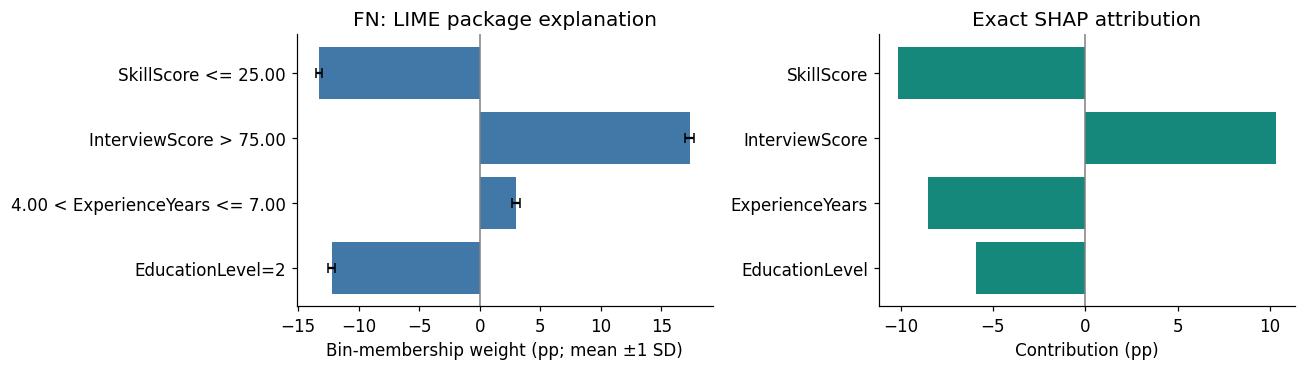

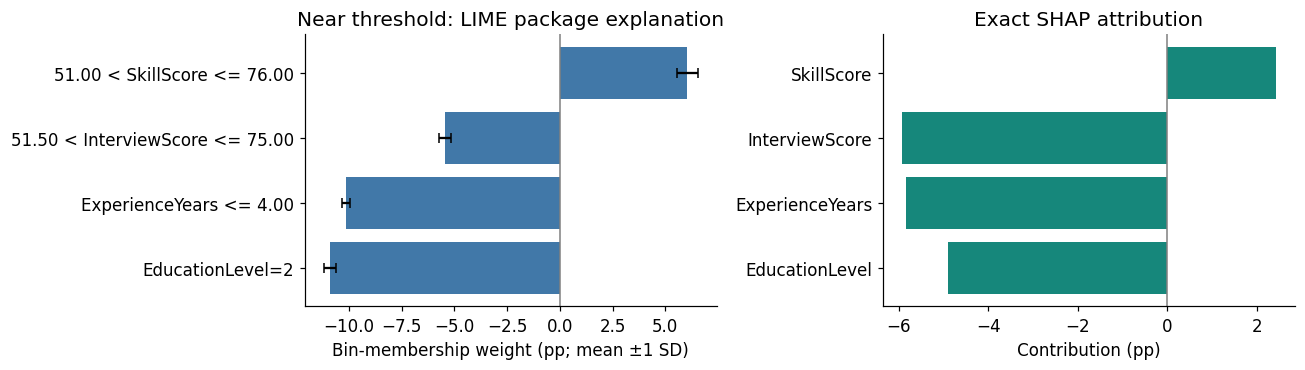

หาก weighted R² ต่ำหรือคำอธิบายต่างกัน ให้ตรวจ neighborhood, background และความสัมพันธ์ของตัวแปรก่อนส่งให้ HR; ห้ามเลือกเฉพาะ seed ที่ดูดี

**ผลที่พบ:** weighted R² เฉลี่ยของแต่ละกรณีอยู่ที่ 0.23–0.48 จึงอธิบายความแปรปรวนใน neighborhood ได้เพียงบางส่วน ไม่ควรใช้ LIME เป็นเหตุผลรายบุคคลเพียงอย่างเดียว LIME อธิบายการอยู่ในช่วงค่าของตัวแปร ขณะที่ SHAP แจกแจงส่วนต่างจาก background จึงไม่ควรเทียบเครื่องหมายราวกับเป็นคำถามเดียวกัน

In [21]:
from lime.lime_tabular import LimeTabularExplainer
from importlib.metadata import version

def explain_with_lime(model,row,train,random_seed,n=5000):
    med=train.median()
    anchor=row.fillna(med)
    explainer=LimeTabularExplainer(
        training_data=train.fillna(med).to_numpy(dtype=float),
        feature_names=features,class_names=['Not hired','Hired'],
        categorical_features=[0],mode='classification',discretize_continuous=True,
        discretizer='quartile',kernel_width=.75*np.sqrt(len(features)),
        feature_selection='none',random_state=random_seed)
    def predict(values):
        return model.predict_proba(pd.DataFrame(values,columns=features))
    explanation=explainer.explain_instance(anchor.to_numpy(dtype=float),predict,
        labels=(1,),num_features=len(features),num_samples=n)
    coef=np.zeros(len(features))
    for j,weight in explanation.local_exp[1]: coef[j]=weight
    labels={j:text for (j,_),(text,_) in zip(explanation.local_exp[1],explanation.as_list(label=1))}
    model_pred=float(model.predict_proba(row.to_frame().T)[:,1][0])
    assert abs(float(explanation.predict_proba[1])-model_pred)<1e-10
    assert abs(explanation.intercept[1]+coef.sum()-float(explanation.local_pred[0]))<1e-10
    return dict(coef=coef,r2=float(explanation.score),local_pred=float(explanation.local_pred[0]),
                model_pred=model_pred,labels=labels,explanation=explanation)

lime_rows=[]; lime_coefs={}; lime_representative={}
lime_dir=root/'lime_explanations'; lime_dir.mkdir(exist_ok=True)
display(Markdown(f'ใช้แพ็กเกจ **lime {version("lime")}** — 5,000 samples × 10 seeds ต่อกรณี'))
for case in cases:
    model,tr,te,cut=fitted[case['fold']-1]
    row=X.iloc[case['row']-2]
    results=[explain_with_lime(model,row,X.iloc[tr],s) for s in range(10)]
    key=case['type']; lime_coefs[key]=np.array([r['coef'] for r in results]); lime_representative[key]=results[0]
    results[0]['explanation'].save_to_file(str(lime_dir/(key.replace(' ','_')+'.html')),labels=[1])
    for s,r in enumerate(results):
        lime_rows.append(dict(case=key,row=case['row'],seed=s,weighted_R2=r['r2'],
                              local_prediction=r['local_pred'],model_prediction=r['model_pred'],
                              absolute_error=abs(r['local_pred']-r['model_pred']),
                              score_basis='package_weighted_training_neighborhood',
                              lime_version=version('lime'),num_samples=5000))
lime_checks=pd.DataFrame(lime_rows)
stability_rows=[]
for case in cases:
    key=case['type']; coefs=lime_coefs[key]
    top=np.argmax(abs(coefs),axis=1); mode=int(np.bincount(top,minlength=4).argmax())
    shap_top=int(np.argmax(np.abs(case['phi'])))
    stability_rows.append(dict(case=key,most_common_top=features[mode],top_agreement=float(np.mean(top==mode)),
                               agreement_with_SHAP_top=float(np.mean(top==shap_top)),
                               mean_weighted_R2=lime_checks.loc[lime_checks['case'].eq(key),'weighted_R2'].mean()))
lime_stability=pd.DataFrame(stability_rows)
display(lime_checks.groupby('case')[['weighted_R2','absolute_error']].agg(['mean','min','max']).round(3))
display(lime_stability.round(3))
fig,axes=plt.subplots(1,2,figsize=(12,4))
case_names=list(lime_coefs)
axes[0].boxplot([lime_checks.loc[lime_checks['case'].eq(k),'weighted_R2'] for k in case_names],tick_labels=case_names)
axes[0].set(title='LIME package fidelity across seeds',ylabel='Weighted training-neighborhood R²')
for k in case_names:
    axes[1].plot(features,lime_coefs[k].std(axis=0,ddof=1),marker='o',label=k)
axes[1].set(title='Local coefficient variability',ylabel='Coefficient SD (probability units)')
axes[1].tick_params(axis='x',rotation=25); axes[1].legend()
plt.tight_layout(); plt.show()
# Bin-membership coefficients and SHAP attributions use different reference questions.
for case in cases:
    key=case['type']; c=lime_coefs[key]
    fig,axes=plt.subplots(1,2,figsize=(12,3.5))
    labels=[lime_representative[key]['labels'][j] for j in range(len(features))]
    axes[0].barh(labels,c.mean(axis=0)*100,xerr=c.std(axis=0,ddof=1)*100,color=COLORS[1],capsize=3)
    axes[0].set(title=f'{key}: LIME package explanation',xlabel='Bin-membership weight (pp; mean ±1 SD)')
    axes[1].barh(features,np.array(case['phi'])*100,color=COLORS[2])
    axes[1].set(title='Exact SHAP attribution',xlabel='Contribution (pp)')
    for ax in axes: ax.axvline(0,color='gray',linewidth=1)
    plt.tight_layout(); plt.show()
display(Markdown('หาก weighted R² ต่ำหรือคำอธิบายต่างกัน ให้ตรวจ neighborhood, background และความสัมพันธ์ของตัวแปรก่อนส่งให้ HR; ห้ามเลือกเฉพาะ seed ที่ดูดี'))
lo=lime_stability.mean_weighted_R2.min(); hi=lime_stability.mean_weighted_R2.max()
display(Markdown(f'**ผลที่พบ:** weighted R² เฉลี่ยของแต่ละกรณีอยู่ที่ {lo:.2f}–{hi:.2f} '
                 'จึงอธิบายความแปรปรวนใน neighborhood ได้เพียงบางส่วน ไม่ควรใช้ LIME เป็นเหตุผลรายบุคคลเพียงอย่างเดียว '
                 'LIME อธิบายการอยู่ในช่วงค่าของตัวแปร ขณะที่ SHAP แจกแจงส่วนต่างจาก background จึงไม่ควรเทียบเครื่องหมายราวกับเป็นคำถามเดียวกัน'))

## 9F. ข้อความร่างสำหรับผู้สมัครและแนวทาง HR
ข้อความต่อไปนี้สร้างจากผลจริง แต่ **ยังไม่ได้รับการตรวจโดย HR** และไม่ใช่เหตุผลปฏิเสธงาน
ไม่อ้างว่าผู้สมัครจะได้งานหากเปลี่ยนตัวแปรใด ไม่สมมติช่องทางติดต่อที่ไม่มีอยู่จริง
ก่อนใช้จริงหน่วยงานต้องกำหนดชื่อผู้รับผิดชอบ ช่องทางติดต่อ และระยะเวลาทบทวน
HR ต้องทวนแฟ้มคะแนนต่ำด้วยเพื่อลดการเสียโอกาสเมื่อคิวมีจำกัด

In [22]:
candidate_drafts=[]
for case in cases:
    phi=np.array(case['phi']); order=np.argsort(-abs(phi))[:2]
    parts=[]
    for j in order:
        direction='เพิ่ม' if phi[j]>=0 else 'ลด'
        parts.append(f"{features[j]} (ค่าที่บันทึก {case['inputs'][features[j]]}) {direction}คะแนนประมาณ {abs(phi[j])*100:.1f} จุดเปอร์เซ็นต์")
    draft=(f"### ร่างสำหรับ HR ตรวจ — แถว CSV {case['row']} ({case['type']})\n"
           'ระบบทดลองใช้ข้อมูลหลังสัมภาษณ์เพื่อช่วยจัดลำดับแฟ้มให้เจ้าหน้าที่ทบทวน ไม่ใช่การตัดสินรับหรือปฏิเสธงาน '
           + 'เมื่อเทียบกับกลุ่มอ้างอิงในข้อมูลฝึก ปัจจัยเด่นคือ '+ '; '.join(parts)+'. '
           'โปรดตรวจว่าระดับการศึกษา ประสบการณ์ และคะแนนที่บันทึกถูกต้อง หากต้องการแก้ไขหรือขอทบทวน '
           'ให้ติดต่อผู้รับผิดชอบการสรรหาผ่านช่องทางที่หน่วยงานประกาศ (ต้องกำหนดก่อนใช้งานจริง). '
           'คำอธิบายนี้สะท้อนรูปแบบในข้อมูลสังเคราะห์ ไม่ใช่ข้อสรุปเกี่ยวกับความสามารถจริงของผู้สมัคร')
    candidate_drafts.append(draft); display(Markdown(draft))
display(Markdown('**ข้อจำกัดก่อนใช้งาน:** ต้องยืนยันเวลาเก็บตัวแปรก่อนจุดตัด ตรวจเกณฑ์ฉลากกับ HR '
                 'ตรวจด้วยข้อมูลจริงที่ได้รับอนุญาต และกำหนดกำลังคน/เวลาสำหรับทบทวนแฟ้ม '
                 'ผลการทดลองและความเป็นธรรมในข้อมูลสังเคราะห์ไม่รับประกันผลในงานจริง'))

### ร่างสำหรับ HR ตรวจ — แถว CSV 570 (TP)
ระบบทดลองใช้ข้อมูลหลังสัมภาษณ์เพื่อช่วยจัดลำดับแฟ้มให้เจ้าหน้าที่ทบทวน ไม่ใช่การตัดสินรับหรือปฏิเสธงาน เมื่อเทียบกับกลุ่มอ้างอิงในข้อมูลฝึก ปัจจัยเด่นคือ EducationLevel (ค่าที่บันทึก 2.0) ลดคะแนนประมาณ 7.0 จุดเปอร์เซ็นต์; SkillScore (ค่าที่บันทึก 21.0) ลดคะแนนประมาณ 6.4 จุดเปอร์เซ็นต์. โปรดตรวจว่าระดับการศึกษา ประสบการณ์ และคะแนนที่บันทึกถูกต้อง หากต้องการแก้ไขหรือขอทบทวน ให้ติดต่อผู้รับผิดชอบการสรรหาผ่านช่องทางที่หน่วยงานประกาศ (ต้องกำหนดก่อนใช้งานจริง). คำอธิบายนี้สะท้อนรูปแบบในข้อมูลสังเคราะห์ ไม่ใช่ข้อสรุปเกี่ยวกับความสามารถจริงของผู้สมัคร

### ร่างสำหรับ HR ตรวจ — แถว CSV 1011 (FP)
ระบบทดลองใช้ข้อมูลหลังสัมภาษณ์เพื่อช่วยจัดลำดับแฟ้มให้เจ้าหน้าที่ทบทวน ไม่ใช่การตัดสินรับหรือปฏิเสธงาน เมื่อเทียบกับกลุ่มอ้างอิงในข้อมูลฝึก ปัจจัยเด่นคือ InterviewScore (ค่าที่บันทึก 66.0) ลดคะแนนประมาณ 8.2 จุดเปอร์เซ็นต์; EducationLevel (ค่าที่บันทึก 2.0) ลดคะแนนประมาณ 6.8 จุดเปอร์เซ็นต์. โปรดตรวจว่าระดับการศึกษา ประสบการณ์ และคะแนนที่บันทึกถูกต้อง หากต้องการแก้ไขหรือขอทบทวน ให้ติดต่อผู้รับผิดชอบการสรรหาผ่านช่องทางที่หน่วยงานประกาศ (ต้องกำหนดก่อนใช้งานจริง). คำอธิบายนี้สะท้อนรูปแบบในข้อมูลสังเคราะห์ ไม่ใช่ข้อสรุปเกี่ยวกับความสามารถจริงของผู้สมัคร

### ร่างสำหรับ HR ตรวจ — แถว CSV 1400 (FN)
ระบบทดลองใช้ข้อมูลหลังสัมภาษณ์เพื่อช่วยจัดลำดับแฟ้มให้เจ้าหน้าที่ทบทวน ไม่ใช่การตัดสินรับหรือปฏิเสธงาน เมื่อเทียบกับกลุ่มอ้างอิงในข้อมูลฝึก ปัจจัยเด่นคือ InterviewScore (ค่าที่บันทึก 80.0) เพิ่มคะแนนประมาณ 10.3 จุดเปอร์เซ็นต์; SkillScore (ค่าที่บันทึก 8.0) ลดคะแนนประมาณ 10.2 จุดเปอร์เซ็นต์. โปรดตรวจว่าระดับการศึกษา ประสบการณ์ และคะแนนที่บันทึกถูกต้อง หากต้องการแก้ไขหรือขอทบทวน ให้ติดต่อผู้รับผิดชอบการสรรหาผ่านช่องทางที่หน่วยงานประกาศ (ต้องกำหนดก่อนใช้งานจริง). คำอธิบายนี้สะท้อนรูปแบบในข้อมูลสังเคราะห์ ไม่ใช่ข้อสรุปเกี่ยวกับความสามารถจริงของผู้สมัคร

### ร่างสำหรับ HR ตรวจ — แถว CSV 310 (Near threshold)
ระบบทดลองใช้ข้อมูลหลังสัมภาษณ์เพื่อช่วยจัดลำดับแฟ้มให้เจ้าหน้าที่ทบทวน ไม่ใช่การตัดสินรับหรือปฏิเสธงาน เมื่อเทียบกับกลุ่มอ้างอิงในข้อมูลฝึก ปัจจัยเด่นคือ InterviewScore (ค่าที่บันทึก 65.0) ลดคะแนนประมาณ 5.9 จุดเปอร์เซ็นต์; ExperienceYears (ค่าที่บันทึก 3.0) ลดคะแนนประมาณ 5.8 จุดเปอร์เซ็นต์. โปรดตรวจว่าระดับการศึกษา ประสบการณ์ และคะแนนที่บันทึกถูกต้อง หากต้องการแก้ไขหรือขอทบทวน ให้ติดต่อผู้รับผิดชอบการสรรหาผ่านช่องทางที่หน่วยงานประกาศ (ต้องกำหนดก่อนใช้งานจริง). คำอธิบายนี้สะท้อนรูปแบบในข้อมูลสังเคราะห์ ไม่ใช่ข้อสรุปเกี่ยวกับความสามารถจริงของผู้สมัคร

**ข้อจำกัดก่อนใช้งาน:** ต้องยืนยันเวลาเก็บตัวแปรก่อนจุดตัด ตรวจเกณฑ์ฉลากกับ HR ตรวจด้วยข้อมูลจริงที่ได้รับอนุญาต และกำหนดกำลังคน/เวลาสำหรับทบทวนแฟ้ม ผลการทดลองและความเป็นธรรมในข้อมูลสังเคราะห์ไม่รับประกันผลในงานจริง

## 10. สรุปผลและข้อจำกัด
เซลล์นี้สรุปจากผลที่รันจริง ไม่ใช้ข้อความสรุปที่กำหนดตัวเลขไว้ล่วงหน้า
AP และ Brier วัดคนละด้าน ส่วน threshold ที่มุ่ง recall สูงอาจเพิ่ม FP
ข้อมูลนี้ยังไม่มีหลักฐานสำหรับยืนยันความถูกต้องของ label ความเป็นตัวแทนของผู้สมัครจริง
หรือประสิทธิภาพในอนาคต ต้องตรวจข้อมูลและบริบทก่อนนำไปใช้งาน

In [23]:
selected = metrics.loc['Selected']
top_feature = features[int(np.argmax(importance_samples.mean(axis=1)))]
recall = selected.tp / (selected.tp + selected.fn)
fpr = selected.fp / (selected.fp + selected.tn)
display(Markdown(
    f"- ผลประเมินนอกชุดฝึก: AP **{selected.ap:.3f}**, Brier **{selected.brier:.3f}**\n"
    f"- Recall **{recall:.1%}**, FPR **{fpr:.1%}** ณ threshold ที่เลือกภายในแต่ละ fold\n"
    f"- โมเดลพึ่งพา **{top_feature}** มากที่สุดตาม permutation importance\n"
    "- ใช้กราฟรายบุคคลเพื่ออธิบายคำทำนาย และตรวจความผิดพลาดร่วมกับผู้เชี่ยวชาญ"
))

- ผลประเมินนอกชุดฝึก: AP **0.614**, Brier **0.175**
- Recall **90.1%**, FPR **66.0%** ณ threshold ที่เลือกภายในแต่ละ fold
- โมเดลพึ่งพา **EducationLevel** มากที่สุดตาม permutation importance
- ใช้กราฟรายบุคคลเพื่ออธิบายคำทำนาย และตรวจความผิดพลาดร่วมกับผู้เชี่ยวชาญ

## 11. บันทึกผลสำหรับใช้งานต่อ
บันทึก JSON และ CSV เหมือนสคริปต์เดิม โดยไม่พิมพ์เนื้อหา JSON ทั้งหมดออกหน้าจอ
กราฟและคำอธิบายจะอยู่ใน Notebook เมื่อกด Save หลัง Run All

In [24]:
pfi_export=importance_samples
result=dict(sklearn=sklearn.__version__,sha256=hashlib.sha256(source.read_bytes()).hexdigest(),n=len(data),positive=int(y.sum()),missing=int(data.ExperienceYears.isna().sum()),splits=splits,metrics={name:summary(y,pred[:,i],dec[:,i]) for i,name in enumerate(names+['Selected'])},groups=groups,pfi_mean=pfi_export.mean(axis=1).tolist(),pfi_sd=pfi_export.std(axis=1,ddof=1).tolist(),features=features,cases=cases)
(root/'model_card_results.json').write_text(json.dumps(result,indent=2,ensure_ascii=False),encoding='utf-8')
pd.DataFrame(records).sort_values('row').to_csv(root/'model_card_predictions.csv',index=False)

display(Markdown('บันทึก **model_card_results.json** และ **model_card_predictions.csv** แล้ว'))

บันทึก **model_card_results.json** และ **model_card_predictions.csv** แล้ว

In [25]:
audit_metrics.to_csv(root / 'model_card_metrics_full.csv', index=False)
fairness.to_csv(root / 'model_card_fairness.csv', index=False)
fairness_gaps.to_csv(root / 'model_card_fairness_gaps.csv', index=False)
grouped_pfi.to_csv(root / 'model_card_grouped_pfi.csv', index=False)
lime_checks.to_csv(root / 'model_card_lime_checks.csv', index=False)
lime_stability.to_csv(root / 'model_card_lime_stability.csv', index=False)
(root / 'candidate_review_drafts.md').write_text('\n\n'.join(candidate_drafts), encoding='utf-8')
display(Markdown('บันทึกตารางตรวจสอบและข้อความร่างสำหรับ HR แล้ว'))

บันทึกตารางตรวจสอบและข้อความร่างสำหรับ HR แล้ว